# 고속도로 구간별 정체 예측 Transformer 모델
**예측 대상:** VOL(교통량), SPD(속도), OCC(점유율)  
**모델:** Transformer Encoder (Multi-output)  
**튜닝:** Optuna TPE + MedianPruner (LSTM과 동일 방식)  

> **입력/출력 구조는 LSTM 노트북과 완전히 동일합니다.**  
> 섹션 1~3(데이터 로드·전처리·시퀀스 생성)은 LSTM과 **동일한 코드**입니다.  
> 섹션 4부터 Transformer 전용 구조가 시작됩니다.

## 0. 라이브러리 설치 및 임포트

In [1]:
# 필요 패키지 설치 (최초 1회)
# !pip install torch scikit-learn pandas numpy matplotlib seaborn tqdm optuna -q

In [2]:
import os
import gc
import glob
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from datetime import datetime
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import optuna
from optuna.samplers import TPESampler
import optuna.visualization.matplotlib as ovm

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 재현성 고정
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 디바이스: {DEVICE}')
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(f'Optuna 버전: {optuna.__version__}')

d:\Python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


사용 디바이스: cuda
True
NVIDIA GeForce RTX 5070
Optuna 버전: 4.8.0


## 1. 데이터 로드

In [4]:
# ⚙️ 데이터 폴더 경로 (LSTM과 동일하게 맞추세요)
DATA_DIR = "D:\\엔지니어링 공모전\\data_set\\program01_data_finish"  # CSV 파일들이 있는 폴더

csv_files = glob.glob(os.path.join(DATA_DIR, '*.csv'))
print(f'발견된 CSV 파일 수: {len(csv_files)}')

df_list = []
for f in tqdm(csv_files, desc='CSV 로딩'):
    tmp = pd.read_csv(f, encoding='utf-8-sig')
    df_list.append(tmp)

df = pd.concat(df_list, ignore_index=True)
print(f'전체 데이터 shape: {df.shape}')
df.head(3)

발견된 CSV 파일 수: 160


CSV 로딩: 100%|██████████| 160/160 [00:22<00:00,  7.05it/s]


전체 데이터 shape: (16491792, 25)


,DATE_CD,ROUTE_ID,ROUTE_NAME,LINK_ID,ROAD_NAME,HH5M_CD,VOL,SPD,OCC,day_sin,...,weekday,month,hour,acc_weekday,acc_month,acc_hour,강수량(mm),적설(cm),시정(10m),is_holiday
0,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,0.0,87.0,86.10,3.60,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1
1,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,5.0,82.0,92.24,3.04,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1
2,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,10.0,90.0,88.76,3.69,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1


## 2. 데이터 전처리

### 2-1. 컬럼 정리 및 결측치 처리

In [5]:
df.columns = df.columns.str.strip().str.replace('\ufeff', '')

USE_COLS = [
    'ROUTE_ID', 'LINK_ID',
    'VOL', 'SPD', 'OCC',
    'day_sin', 'day_cos', 'hour_sin', 'hour_cos',
    'Past SPD', 'date',
    'acc_weekday', 'acc_month', 'acc_hour',
    '강수량(mm)', '적설(cm)', '시정(10m)', 'is_holiday'
]

df = df[USE_COLS].copy()
print('결측치:\n', df.isnull().sum())

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].interpolate(method='linear', limit_direction='both')
df.fillna(0, inplace=True)

df['date'] = pd.to_datetime(df['date'])
df.sort_values(['LINK_ID', 'date'], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'정리 후 shape: {df.shape}')

결측치:
 ROUTE_ID         0
LINK_ID          0
VOL            111
SPD              0
OCC             51
day_sin          0
day_cos          0
hour_sin         0
hour_cos         0
Past SPD         0
date             0
acc_weekday      0
acc_month        0
acc_hour         0
강수량(mm)          0
적설(cm)           0
시정(10m)          0
is_holiday       0
dtype: int64
정리 후 shape: (16491792, 18)


### 2-2. 요일 원핫인코딩

In [6]:
df['weekday'] = df['date'].dt.dayofweek
weekday_ohe = pd.get_dummies(df['weekday'], prefix='wd').astype(np.float32)
for i in range(7):
    col = f'wd_{i}'
    if col not in weekday_ohe.columns:
        weekday_ohe[col] = 0.0
weekday_ohe = weekday_ohe[[f'wd_{i}' for i in range(7)]]
df = pd.concat([df, weekday_ohe], axis=1)
df.drop(columns=['weekday', 'date'], inplace=True)
WEEKDAY_COLS = [f'wd_{i}' for i in range(7)]
print('요일 원핫인코딩 완료:', WEEKDAY_COLS)

요일 원핫인코딩 완료: ['wd_0', 'wd_1', 'wd_2', 'wd_3', 'wd_4', 'wd_5', 'wd_6']


### 2-3. ROUTE_ID / LINK_ID 임베딩 인코딩

In [7]:
route_enc = LabelEncoder()
link_enc  = LabelEncoder()
df['ROUTE_ID_enc'] = route_enc.fit_transform(df['ROUTE_ID'].astype(str))
df['LINK_ID_enc']  = link_enc.fit_transform(df['LINK_ID'].astype(str))

NUM_ROUTES    = df['ROUTE_ID_enc'].nunique()
NUM_LINKS     = df['LINK_ID_enc'].nunique()
ROUTE_EMB_DIM = min(50, (NUM_ROUTES + 1) // 2)
LINK_EMB_DIM  = min(50, (NUM_LINKS  + 1) // 2)

print(f'ROUTE_ID 고유값: {NUM_ROUTES}, 임베딩 차원: {ROUTE_EMB_DIM}')
print(f'LINK_ID  고유값: {NUM_LINKS},  임베딩 차원: {LINK_EMB_DIM}')
df.drop(columns=['ROUTE_ID', 'LINK_ID'], inplace=True)

ROUTE_ID 고유값: 16, 임베딩 차원: 8
LINK_ID  고유값: 160,  임베딩 차원: 50


### 2-4. 수치형 피처 스케일링

In [8]:
scalers = {}

df['VOL_log'] = np.log1p(df['VOL'])
scalers['VOL'] = StandardScaler()
df['VOL_scaled'] = scalers['VOL'].fit_transform(df[['VOL_log']])

scalers['SPD'] = StandardScaler()
df['SPD_scaled'] = scalers['SPD'].fit_transform(df[['SPD']])

df['OCC_log'] = np.log1p(df['OCC'])
scalers['OCC'] = StandardScaler()
df['OCC_scaled'] = scalers['OCC'].fit_transform(df[['OCC_log']])

scalers['Past_SPD'] = StandardScaler()
df['Past_SPD_scaled'] = scalers['Past_SPD'].fit_transform(df[['Past SPD']])

for col in ['acc_weekday', 'acc_month', 'acc_hour']:
    scalers[col] = MinMaxScaler()
    df[f'{col}_scaled'] = scalers[col].fit_transform(df[[col]])

for col in ['강수량(mm)', '적설(cm)']:
    key = col.replace('(', '').replace(')', '').replace('/', '')
    df[f'{key}_log'] = np.log1p(df[col])
    scalers[key] = MinMaxScaler()
    df[f'{key}_scaled'] = scalers[key].fit_transform(df[[f'{key}_log']])

df['visibility_scaled'] = np.log1p(df['시정(10m)'])
df['is_holiday'] = df['is_holiday'].astype(np.float32)
print('스케일링 완료')

스케일링 완료


### 2-5. 최종 피처 컬럼 정의

In [9]:
NUM_FEATURES = [
    'VOL_scaled', 'SPD_scaled', 'OCC_scaled',
    'day_sin', 'day_cos',
    'hour_sin', 'hour_cos',
    'Past_SPD_scaled',
    'acc_weekday_scaled', 'acc_month_scaled', 'acc_hour_scaled',
    '강수량mm_scaled', '적설cm_scaled',
    'visibility_scaled',
    'is_holiday'
] + WEEKDAY_COLS

CAT_FEATURES = ['ROUTE_ID_enc', 'LINK_ID_enc']
TARGET_COLS  = ['VOL_scaled', 'SPD_scaled', 'OCC_scaled']

print(f'수치형 입력 피처 수: {len(NUM_FEATURES)}')
print(f'수치형 피처 목록: {NUM_FEATURES}')

수치형 입력 피처 수: 22
수치형 피처 목록: ['VOL_scaled', 'SPD_scaled', 'OCC_scaled', 'day_sin', 'day_cos', 'hour_sin', 'hour_cos', 'Past_SPD_scaled', 'acc_weekday_scaled', 'acc_month_scaled', 'acc_hour_scaled', '강수량mm_scaled', '적설cm_scaled', 'visibility_scaled', 'is_holiday', 'wd_0', 'wd_1', 'wd_2', 'wd_3', 'wd_4', 'wd_5', 'wd_6']


## 3. 시퀀스 데이터셋 생성

In [10]:
SEQ_LEN    = 12  # LSTM과 동일
PRED_STEPS = 3   # LSTM과 동일

def make_sequences(group_df, seq_len, pred_steps):
    X_num_list, X_cat_list, y_list = [], [], []
    num_arr = group_df[NUM_FEATURES].values.astype(np.float32)
    cat_arr = group_df[CAT_FEATURES].values.astype(np.int64)
    tgt_arr = group_df[TARGET_COLS].values.astype(np.float32)
    for i in range(len(group_df) - seq_len - pred_steps + 1):
        X_num_list.append(num_arr[i : i + seq_len])
        X_cat_list.append(cat_arr[i])
        y_list.append(tgt_arr[i + seq_len : i + seq_len + pred_steps].flatten())
    return X_num_list, X_cat_list, y_list

all_X_num, all_X_cat, all_y = [], [], []
for link_id, group in tqdm(df.groupby('LINK_ID_enc'), desc='시퀀스 생성'):
    group = group.reset_index(drop=True)
    if len(group) < SEQ_LEN + PRED_STEPS:
        continue
    xn, xc, y = make_sequences(group, SEQ_LEN, PRED_STEPS)
    all_X_num.extend(xn)
    all_X_cat.extend(xc)
    all_y.extend(y)

X_num = np.array(all_X_num, dtype=np.float32)
X_cat = np.array(all_X_cat, dtype=np.int64)
y_arr = np.array(all_y,     dtype=np.float32)

print(f'X_num shape: {X_num.shape}')
print(f'X_cat shape: {X_cat.shape}')
print(f'y     shape: {y_arr.shape}')

시퀀스 생성: 100%|██████████| 160/160 [00:21<00:00,  7.45it/s]


X_num shape: (16489552, 12, 22)
X_cat shape: (16489552, 2)
y     shape: (16489552, 9)


In [32]:
# 저장 경로 설정 (본인 환경에 맞게 수정)
SAVE_DIR = "D:\\엔지니어링 공모전\\python_code\\second_program\\ensemble_val_num"   # 저장할 폴더
os.makedirs(SAVE_DIR, exist_ok=True)

np.save(os.path.join(SAVE_DIR, 'X_num_val.npy'), X_num_val)
np.save(os.path.join(SAVE_DIR, 'X_cat_val.npy'), X_cat_val)
np.save(os.path.join(SAVE_DIR, 'y_val.npy'),     y_val)
np.save(os.path.join(SAVE_DIR, 'X_num_te.npy'),  X_num_te)
np.save(os.path.join(SAVE_DIR, 'X_cat_te.npy'),  X_cat_te)
np.save(os.path.join(SAVE_DIR, 'y_te.npy'),      y_te)
print('저장 완료:', SAVE_DIR)

저장 완료: D:\엔지니어링 공모전\python_code\second_program\ensemble_val_num


In [11]:
N = len(X_num)
train_end = int(N * 0.7)
val_end   = int(N * 0.85)

X_num_tr,  X_num_val,  X_num_te  = X_num[:train_end], X_num[train_end:val_end], X_num[val_end:]
X_cat_tr,  X_cat_val,  X_cat_te  = X_cat[:train_end], X_cat[train_end:val_end], X_cat[val_end:]
y_tr,      y_val,      y_te      = y_arr[:train_end], y_arr[train_end:val_end], y_arr[val_end:]

print(f'Train: {len(y_tr):,} | Val: {len(y_val):,} | Test: {len(y_te):,}')

Train: 11,542,686 | Val: 2,473,433 | Test: 2,473,433


## 4. PyTorch Dataset & DataLoader

In [12]:
class TrafficDataset(Dataset):
    def __init__(self, x_num, x_cat, y):
        self.x_num = x_num
        self.x_cat = x_cat
        self.y     = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.x_num[idx], dtype=torch.float32),
            torch.tensor(self.x_cat[idx], dtype=torch.long),
            torch.tensor(self.y[idx],     dtype=torch.float32)
        )


BATCH_SIZE = 4096

train_ds = TrafficDataset(X_num_tr, X_cat_tr, y_tr)
val_ds   = TrafficDataset(X_num_val, X_cat_val, y_val)
test_ds  = TrafficDataset(X_num_te, X_cat_te, y_te)

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=True, persistent_workers=False)

train_loader = make_loader(train_ds, shuffle=True)
val_loader   = make_loader(val_ds,   shuffle=False)
test_loader  = make_loader(test_ds,  shuffle=False)
print('DataLoader 생성 완료')

DataLoader 생성 완료


## 5. Transformer 모델 정의

**구조 설명:**
```
ROUTE_ID ──► Embedding ─┐
LINK_ID  ──► Embedding ─┤
                        ├─► concat ──► Linear(proj) ──► + PositionalEncoding
수치형 피처(22개) ───────┘                                        │
                                                         TransformerEncoder
                                                         (N layers, H heads)
                                                                 │
                                                    [CLS token 출력] or [평균 풀링]
                                                                 │
                                                        FC Head → VOL/SPD/OCC
                                                     (PRED_STEPS × 3 출력)
```
**LSTM과의 차이점:**
- LSTM: 순차적으로 처리 → 마지막 hidden state 사용  
- Transformer: 전체 시퀀스를 병렬 처리 → Self-Attention으로 장기 패턴 포착

In [13]:
class PositionalEncoding(nn.Module):
    """사인/코사인 Positional Encoding — 시계열 위치 정보 주입"""
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))  # (1, max_len, d_model)

    def forward(self, x):
        # x: (B, seq_len, d_model)
        return self.dropout(x + self.pe[:, :x.size(1)])


class TrafficTransformer(nn.Module):
    def __init__(
        self,
        num_numeric_features,
        num_routes, route_emb_dim,
        num_links,  link_emb_dim,
        d_model     = 128,   # Transformer 내부 차원
        nhead       = 4,     # Attention head 수 (d_model의 약수여야 함)
        num_layers  = 2,     # Encoder layer 수
        dim_ff      = 256,   # FeedForward 내부 차원
        dropout     = 0.1,
        output_size = 3,     # VOL, SPD, OCC
        pred_steps  = 1
    ):
        super().__init__()

        # 임베딩
        self.route_emb = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb  = nn.Embedding(num_links,  link_emb_dim)

        # 입력 차원 → d_model 투영
        input_dim = num_numeric_features + route_emb_dim + link_emb_dim
        self.input_proj = nn.Linear(input_dim, d_model)

        # Positional Encoding
        self.pos_enc = PositionalEncoding(d_model, dropout=dropout)

        # Transformer Encoder
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,   # (B, seq, d_model) 형태 사용
            norm_first=True     # Pre-LN: 학습 안정성↑ (Post-LN 대비)
        )
        self.transformer_enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers)

        # 출력 헤드
        self.head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, output_size * pred_steps)
        )

        self.pred_steps  = pred_steps
        self.output_size = output_size

        # 가중치 초기화
        self._init_weights()

    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, x_num, x_cat):
        # x_num: (B, seq_len, num_features)
        # x_cat: (B, 2)

        # 임베딩 → 시퀀스 전체에 broadcast
        route_e = self.route_emb(x_cat[:, 0])                          # (B, route_emb_dim)
        link_e  = self.link_emb(x_cat[:, 1])                           # (B, link_emb_dim)
        cat_e   = torch.cat([route_e, link_e], dim=-1)                  # (B, emb_total)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)     # (B, seq_len, emb_total)

        # 수치 + 임베딩 결합 → d_model 투영
        x = torch.cat([x_num, cat_e], dim=-1)                          # (B, seq_len, input_dim)
        x = self.input_proj(x)                                          # (B, seq_len, d_model)

        # Positional Encoding
        x = self.pos_enc(x)                                             # (B, seq_len, d_model)

        # Transformer Encoder
        x = self.transformer_enc(x)                                     # (B, seq_len, d_model)

        # 마지막 타임스텝 사용 (예측 직전 시점이 가장 정보량이 많음)
        out = x[:, -1, :]                                               # (B, d_model)

        return self.head(out)                                           # (B, output_size*pred_steps)


# ── 기본값으로 모델 인스턴스 생성 (BO 전 확인용) ──────────────
# BO 완료 후 섹션 6-BO-apply에서 최적값으로 재생성됩니다.
def build_transformer(d_model=128, nhead=4, num_layers=2, dim_ff=256, dropout=0.1):
    # nhead가 d_model의 약수인지 보장
    while d_model % nhead != 0:
        nhead -= 1
    return TrafficTransformer(
        num_numeric_features = len(NUM_FEATURES),
        num_routes           = NUM_ROUTES,
        route_emb_dim        = ROUTE_EMB_DIM,
        num_links            = NUM_LINKS,
        link_emb_dim         = LINK_EMB_DIM,
        d_model              = d_model,
        nhead                = nhead,
        num_layers           = num_layers,
        dim_ff               = dim_ff,
        dropout              = dropout,
        output_size          = 3,
        pred_steps           = PRED_STEPS
    ).to(DEVICE)


model = build_transformer()
print(model)
print(f'\n학습 파라미터 수: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

TrafficTransformer(
  (route_emb): Embedding(16, 8)
  (link_emb): Embedding(160, 50)
  (input_proj): Linear(in_features=80, out_features=128, bias=True)
  (pos_enc): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_enc): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): LayerNorm((128,), eps

## 6-BO. Bayesian Optimization + Pruning (하이퍼파라미터 자동 튜닝)

> **실행 순서:** 섹션 4(DataLoader) 완료 후 → 본 섹션 전체 실행 → 섹션 6~7 실행

### LSTM BO와의 차이점

| 항목 | LSTM BO | Transformer BO |
|------|---------|----------------|
| 탐색 파라미터 | hidden_size, num_layers, dropout, lr, wd | **d_model, nhead, num_layers, dim_ff**, dropout, lr, wd |
| 추가 제약 | 없음 | **d_model % nhead == 0** 보장 필요 |
| Pruner | MedianPruner | **HyperbandPruner** (더 공격적 가지치기, Transformer에 적합) |
| 결과 저장 | bo_results/ | **tr_bo_results/** (구분 저장) |

In [14]:
# ⚙️ BO 설정
BO_N_TRIALS    = 30      # 시도 횟수 (권장 20~50)
BO_EPOCHS      = 5       # trial당 에포크
BO_PATIENCE    = 3       # trial 내 early stopping
BO_SAMPLE_SIZE = 300000  # 서브샘플 크기
BO_BATCH_SIZE  = 4096
TR_BO_DIR      = 'tr_bo_results'
os.makedirs(TR_BO_DIR, exist_ok=True)

print(f'BO 설정: trials={BO_N_TRIALS} | epochs/trial={BO_EPOCHS} | 샘플={BO_SAMPLE_SIZE:,}')

BO 설정: trials=30 | epochs/trial=5 | 샘플=300,000


In [15]:
# BO 전용 서브샘플
np.random.seed(SEED)
bo_idx     = np.random.choice(len(X_num_tr), min(BO_SAMPLE_SIZE, len(X_num_tr)), replace=False)
bo_val_idx = np.random.choice(len(X_num_val), min(50000, len(X_num_val)), replace=False)

bo_train_ds = TrafficDataset(X_num_tr[bo_idx],     X_cat_tr[bo_idx],     y_tr[bo_idx])
bo_val_ds   = TrafficDataset(X_num_val[bo_val_idx], X_cat_val[bo_val_idx], y_val[bo_val_idx])

print(f'BO Train: {len(bo_train_ds):,} | BO Val: {len(bo_val_ds):,}')

BO Train: 300,000 | BO Val: 50,000


In [16]:
bo_trial_records = []

def tr_objective(trial):
    # ── 탐색 공간 ───────────────────────────────────────────
    d_model    = trial.suggest_categorical('d_model',    [64, 128, 256])
    nhead_cand = [h for h in [2, 4, 8] if d_model % h == 0]  # d_model 약수만
    nhead      = trial.suggest_categorical('nhead',      nhead_cand)
    num_layers = trial.suggest_int('num_layers',  1, 4)
    dim_ff     = trial.suggest_categorical('dim_ff',     [128, 256, 512, 1024])
    dropout    = trial.suggest_float('dropout',    0.05, 0.4, step=0.05)
    lr         = trial.suggest_float('lr',         1e-4, 5e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True)

    # ── 모델 생성 ────────────────────────────────────────────
    _model = build_transformer(d_model=d_model, nhead=nhead,
                               num_layers=num_layers, dim_ff=dim_ff, dropout=dropout)
    _opt   = torch.optim.AdamW(_model.parameters(), lr=lr, weight_decay=weight_decay)
    _crit  = nn.MSELoss()
    _amp   = torch.cuda.amp.GradScaler()

    _tl = DataLoader(bo_train_ds, batch_size=BO_BATCH_SIZE, shuffle=True,
                     num_workers=0, pin_memory=True, persistent_workers=False)
    _vl = DataLoader(bo_val_ds,   batch_size=BO_BATCH_SIZE, shuffle=False,
                     num_workers=0, pin_memory=True, persistent_workers=False)

    best_val, pat = float('inf'), 0

    for epoch in range(BO_EPOCHS):
        # Train
        _model.train()
        for xn, xc, y in _tl:
            xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
            _opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = _crit(_model(xn, xc), y)
            _amp.scale(loss).backward()
            _amp.unscale_(_opt)
            nn.utils.clip_grad_norm_(_model.parameters(), 1.0)
            _amp.step(_opt)
            _amp.update()

        # Validate
        _model.eval()
        vl = 0.0
        with torch.no_grad():
            for xn, xc, y in _vl:
                xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
                with torch.cuda.amp.autocast():
                    vl += _crit(_model(xn, xc), y).item() * len(y)
        vl /= len(_vl.dataset)

        trial.report(vl, epoch)
        if trial.should_prune():
            del _model; torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

        if vl < best_val: best_val, pat = vl, 0
        else:
            pat += 1
            if pat >= BO_PATIENCE: break

    del _model, _opt, _tl, _vl
    torch.cuda.empty_cache(); gc.collect()
    return best_val

print('objective 함수 정의 완료')

objective 함수 정의 완료


In [17]:
# HyperbandPruner: Transformer처럼 epoch마다 loss가 다이나믹하게 변하는 경우에 더 효율적
# MedianPruner보다 공격적으로 나쁜 trial을 조기 종료 → 탐색 효율 ↑
study = optuna.create_study(
    direction = 'minimize',
    sampler   = TPESampler(seed=SEED),
    pruner    = optuna.pruners.HyperbandPruner(
        min_resource=1, max_resource=BO_EPOCHS, reduction_factor=3
    )
)

print(f'Bayesian Optimization 시작 (Transformer) | {BO_N_TRIALS} trials')
print('-' * 65)

def _bo_callback(study, trial):
    if trial.value is not None:
        mark = ' ✅ BEST' if trial.value == study.best_value else ''
        print(f'  Trial {trial.number:3d} | Val Loss: {trial.value:.6f}{mark}')
        record = {'trial': trial.number, 'val_loss': round(trial.value, 8),
                  'is_best': trial.value == study.best_value, 'state': 'COMPLETE'}
        record.update(trial.params)
        bo_trial_records.append(record)
    else:
        print(f'  Trial {trial.number:3d} | Pruned ✂️')
        bo_trial_records.append({'trial': trial.number, 'val_loss': None,
                                  'is_best': False, 'state': 'PRUNED'})

study.optimize(tr_objective, n_trials=BO_N_TRIALS, callbacks=[_bo_callback])

print('-' * 65)
print(f'\n✅ BO 완료!  최적 Val Loss: {study.best_value:.6f}')
print('최적 파라미터:')
for k, v in study.best_params.items():
    print(f'  {k:15s} = {v}')

Bayesian Optimization 시작 (Transformer) | 30 trials
-----------------------------------------------------------------
  Trial   0 | Val Loss: 0.071575 ✅ BEST
  Trial   1 | Val Loss: 0.071564 ✅ BEST
  Trial   2 | Val Loss: 0.057658 ✅ BEST
  Trial   3 | Val Loss: 0.085593
  Trial   4 | Val Loss: 0.180648
  Trial   5 | Val Loss: 0.181296
  Trial   6 | Val Loss: 0.045309 ✅ BEST
  Trial   7 | Val Loss: 0.049915
  Trial   8 | Val Loss: 0.086402
  Trial   9 | Val Loss: 0.104993
  Trial  10 | Val Loss: 0.048451
  Trial  11 | Val Loss: 0.042318 ✅ BEST
  Trial  12 | Val Loss: 0.047131
  Trial  13 | Val Loss: 0.047454
  Trial  14 | Val Loss: 0.064030
  Trial  15 | Val Loss: 0.045988
  Trial  16 | Val Loss: 0.051169
  Trial  17 | Val Loss: 0.074779
  Trial  18 | Val Loss: 0.049640
  Trial  19 | Val Loss: 0.053221
  Trial  20 | Val Loss: 0.416349
  Trial  21 | Val Loss: 0.049036
  Trial  22 | Val Loss: 0.044764
  Trial  23 | Val Loss: 0.042547
  Trial  24 | Val Loss: 0.049435
  Trial  25 | Val Loss:

In [18]:
# 최적 파라미터 전역 변수 등록
TR_D_MODEL    = study.best_params['d_model']
TR_NHEAD      = study.best_params['nhead']
TR_NUM_LAYERS = study.best_params['num_layers']
TR_DIM_FF     = study.best_params['dim_ff']
TR_DROPOUT    = study.best_params['dropout']
TR_LR_BEST    = study.best_params['lr']
TR_WD_BEST    = study.best_params['weight_decay']

print('=' * 55)
print('Transformer BO 최적 파라미터')
print(f'  d_model     = {TR_D_MODEL}')
print(f'  nhead       = {TR_NHEAD}')
print(f'  num_layers  = {TR_NUM_LAYERS}')
print(f'  dim_ff      = {TR_DIM_FF}')
print(f'  dropout     = {TR_DROPOUT:.2f}')
print(f'  lr          = {TR_LR_BEST:.6f}')
print(f'  weight_decay= {TR_WD_BEST:.8f}')
print('=' * 55)
print('→ 섹션 6(학습 설정)을 실행하면 자동 적용됩니다.')

Transformer BO 최적 파라미터
  d_model     = 256
  nhead       = 4
  num_layers  = 2
  dim_ff      = 512
  dropout     = 0.05
  lr          = 0.000656
  weight_decay= 0.00000667
→ 섹션 6(학습 설정)을 실행하면 자동 적용됩니다.


In [19]:
# BO 결과 저장 (보고서용)
_ts = datetime.now().strftime('%Y%m%d_%H%M%S')

# 1. 전체 trial CSV
_df_trials = pd.DataFrame(bo_trial_records)
_trials_csv = os.path.join(TR_BO_DIR, f'tr_bo_trials_{_ts}.csv')
_df_trials.to_csv(_trials_csv, index=False, encoding='utf-8-sig')
print(f'[저장] Trial CSV          → {_trials_csv}')

# 2. 최적 파라미터 JSON
_best_json = os.path.join(TR_BO_DIR, f'tr_bo_best_params_{_ts}.json')
_best_info = {
    'timestamp'     : _ts,
    'model'         : 'Transformer',
    'n_trials'      : BO_N_TRIALS,
    'pruner'        : 'HyperbandPruner',
    'best_trial'    : study.best_trial.number,
    'best_val_loss' : study.best_value,
    'best_params'   : study.best_params,
    'search_space'  : {
        'd_model'      : [64, 128, 256],
        'nhead'        : 'd_model의 약수 중 [2,4,8]',
        'num_layers'   : '1 ~ 4',
        'dim_ff'       : [128, 256, 512, 1024],
        'dropout'      : '0.05 ~ 0.40 (step 0.05)',
        'lr'           : '1e-4 ~ 5e-3 (log)',
        'weight_decay' : '1e-6 ~ 1e-3 (log)',
    }
}
with open(_best_json, 'w', encoding='utf-8') as f:
    json.dump(_best_info, f, ensure_ascii=False, indent=2)
print(f'[저장] 최적 파라미터 JSON → {_best_json}')

# 3. Study pickle
_study_pkl = os.path.join(TR_BO_DIR, f'tr_bo_study_{_ts}.pkl')
with open(_study_pkl, 'wb') as f:
    pickle.dump(study, f)
print(f'[저장] Study pickle       → {_study_pkl}')

# 4. 요약 출력
_df_c = _df_trials[_df_trials['state'] == 'COMPLETE']
print(f'\n총 trials: {len(_df_trials)} | 완료: {len(_df_c)} | 가지치기: {len(_df_trials)-len(_df_c)}')
print(f'최적 Trial #{study.best_trial.number} | Val Loss: {study.best_value:.6f}')

[저장] Trial CSV          → tr_bo_results\tr_bo_trials_20260430_193729.csv
[저장] 최적 파라미터 JSON → tr_bo_results\tr_bo_best_params_20260430_193729.json
[저장] Study pickle       → tr_bo_results\tr_bo_study_20260430_193729.pkl

총 trials: 30 | 완료: 30 | 가지치기: 0
최적 Trial #11 | Val Loss: 0.042318


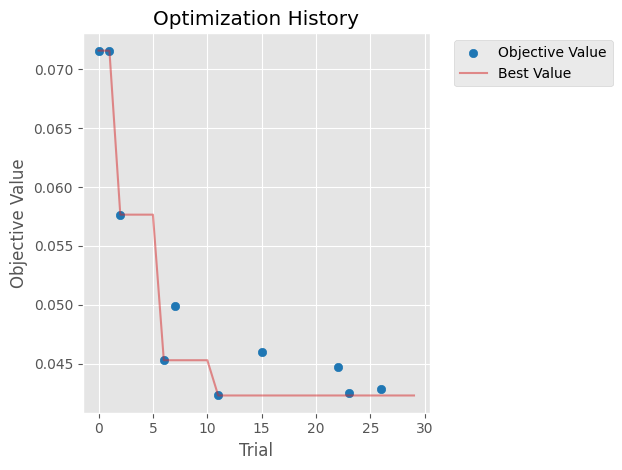

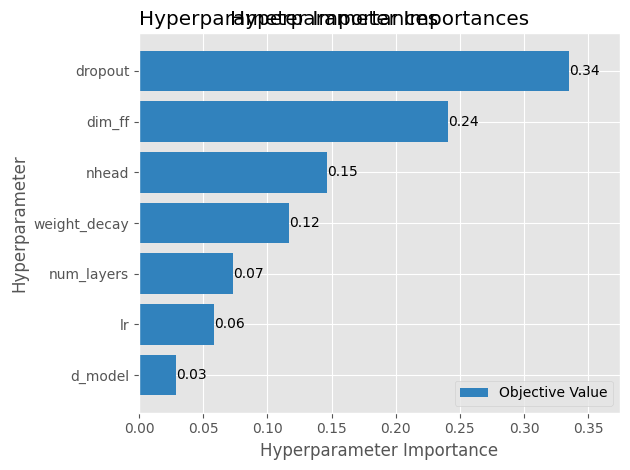

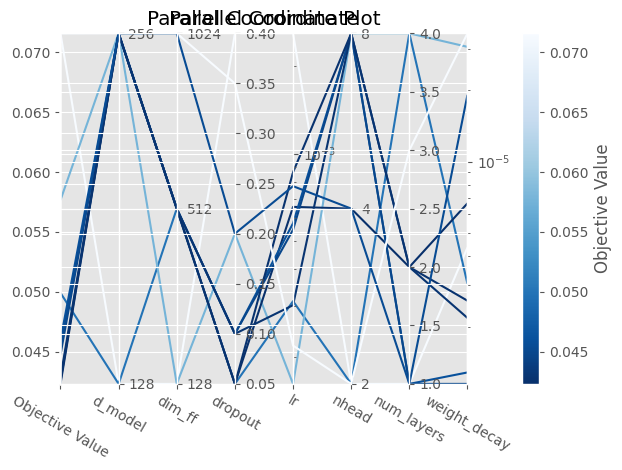

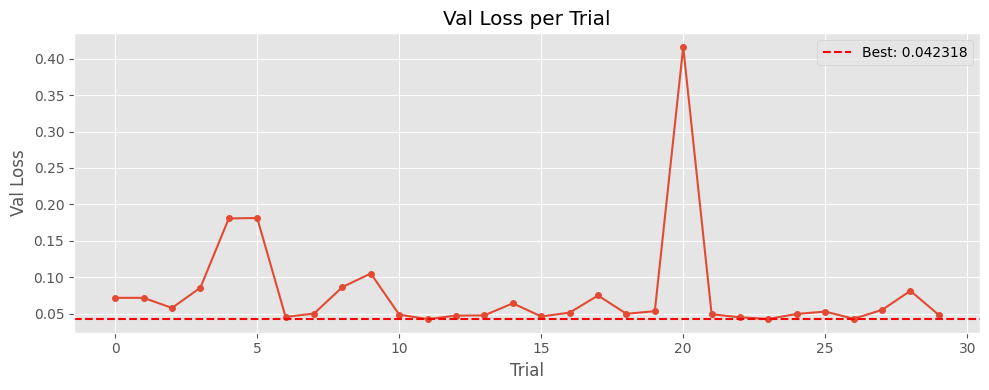

시각화 4종 저장 완료 → tr_bo_results/


In [24]:
_ts2 = datetime.now().strftime('%Y%m%d_%H%M%S')

# 그래프 1: Optimization History
ovm.plot_optimization_history(study)
plt.title('Optimization History')
plt.tight_layout()
plt.savefig(os.path.join(TR_BO_DIR, f'tr_bo_history_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 2: Param Importances
ovm.plot_param_importances(study)
plt.title('Hyperparameter Importances')
plt.tight_layout()
plt.savefig(os.path.join(TR_BO_DIR, f'tr_bo_importance_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 3: Parallel Coordinate
ovm.plot_parallel_coordinate(study)
plt.title('Parallel Coordinate')
plt.tight_layout()
plt.savefig(os.path.join(TR_BO_DIR, f'tr_bo_parallel_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 4: Trial별 Val Loss (커스텀, 직접 그리므로 문제 없음)
_df_c = pd.DataFrame(bo_trial_records)
_df_c = _df_c[_df_c['state'] == 'COMPLETE'].copy()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(_df_c['trial'], _df_c['val_loss'], 'o-', markersize=4)
ax.axhline(study.best_value, color='red', linestyle='--',
           label=f'Best: {study.best_value:.6f}')
ax.set_xlabel('Trial'); ax.set_ylabel('Val Loss')
ax.set_title('Val Loss per Trial'); ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(TR_BO_DIR, f'tr_bo_valloss_{_ts2}.png'), dpi=150)
plt.show()

print(f'시각화 4종 저장 완료 → {TR_BO_DIR}/')

## 6. 학습 설정

In [25]:
EPOCHS   = 50
PATIENCE = 7

# BO 결과가 있으면 최적값, 없으면 기본값
try:
    _dm, _nh, _nl, _df2, _dr = TR_D_MODEL, TR_NHEAD, TR_NUM_LAYERS, TR_DIM_FF, TR_DROPOUT
    _lr, _wd = TR_LR_BEST, TR_WD_BEST
    print(f'✅ BO 최적 파라미터 적용: d_model={_dm}, nhead={_nh}, layers={_nl}, dim_ff={_df2}')
except NameError:
    _dm, _nh, _nl, _df2, _dr = 128, 4, 2, 256, 0.1
    _lr, _wd = 1e-3, 1e-5
    print(f'⚠️  기본값 적용: d_model={_dm}, nhead={_nh}, layers={_nl}')

# 최적 파라미터로 모델 재생성
model = build_transformer(d_model=_dm, nhead=_nh, num_layers=_nl,
                          dim_ff=_df2, dropout=_dr)
print(f'파라미터 수: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

criterion  = nn.MSELoss()
# Transformer에는 AdamW가 Adam보다 일반적으로 더 좋음
optimizer  = torch.optim.AdamW(model.parameters(), lr=_lr, weight_decay=_wd)
# CosineAnnealingLR: Transformer 학습 안정성에 유리
scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=_lr * 0.01
)
scaler_amp = torch.cuda.amp.GradScaler()

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    for xn, xc, y in loader:
        xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            pred = model(xn, xc)
            loss = criterion(pred, y)
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    for xn, xc, y in loader:
        xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
        with torch.cuda.amp.autocast():
            loss = criterion(model(xn, xc), y)
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

print('학습 설정 완료')

✅ BO 최적 파라미터 적용: d_model=256, nhead=4, layers=2, dim_ff=512
파라미터 수: 1,117,641
학습 설정 완료


## 7. 학습 실행

In [26]:
import time

train_losses, val_losses = [], []
best_val_loss = float('inf')
patience_cnt  = 0
SAVE_PATH     = 'best_transformer_model.pt'

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss = train_one_epoch(model, train_loader)
    vl_loss = evaluate(model, val_loader)
    scheduler.step()
    elapsed = time.time() - t0

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        torch.save(model.state_dict(), SAVE_PATH)
        patience_cnt = 0
        marker = ' ✅ saved'
    else:
        patience_cnt += 1
        marker = f' (patience {patience_cnt}/{PATIENCE})'

    print(f'Epoch {epoch:3d}/{EPOCHS} | Train: {tr_loss:.6f} | Val: {vl_loss:.6f} | {elapsed:.1f}s{marker}')

    if patience_cnt >= PATIENCE:
        print(f'\nEarly Stopping at epoch {epoch}')
        break

print(f'\n최적 Val Loss: {best_val_loss:.6f}')

Epoch   1/50 | Train: 0.057997 | Val: 0.045337 | 310.5s ✅ saved
Epoch   2/50 | Train: 0.041437 | Val: 0.043730 | 305.0s ✅ saved
Epoch   3/50 | Train: 0.040099 | Val: 0.043815 | 303.6s (patience 1/7)
Epoch   4/50 | Train: 0.039318 | Val: 0.054534 | 305.6s (patience 2/7)
Epoch   5/50 | Train: 0.038711 | Val: 0.053759 | 303.7s (patience 3/7)
Epoch   6/50 | Train: 0.038213 | Val: 0.055659 | 305.0s (patience 4/7)
Epoch   7/50 | Train: 0.037804 | Val: 0.058581 | 303.9s (patience 5/7)
Epoch   8/50 | Train: 0.037401 | Val: 0.058126 | 304.3s (patience 6/7)
Epoch   9/50 | Train: 0.037075 | Val: 0.053758 | 304.5s (patience 7/7)

Early Stopping at epoch 9

최적 Val Loss: 0.043730


## 8. 학습 곡선 시각화

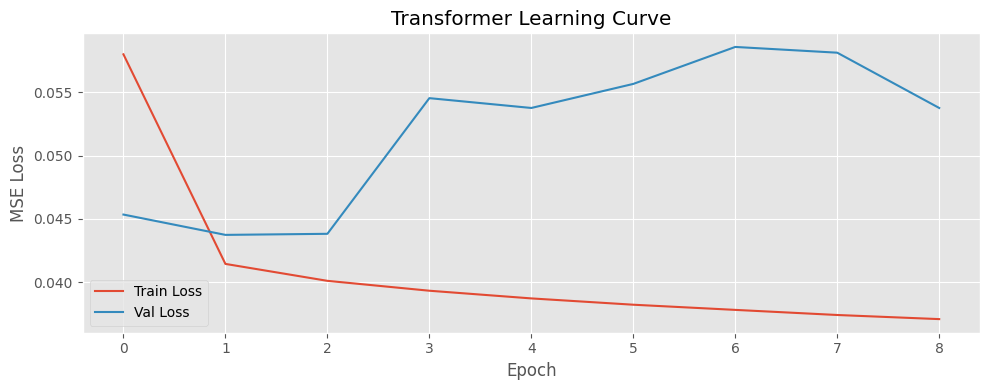

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses,   label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('Transformer Learning Curve')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('tr_learning_curve.png', dpi=150)
plt.show()

## 9. 테스트 평가

In [28]:
model.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
model.eval()

all_preds, all_trues = [], []
with torch.no_grad():
    for xn, xc, y in test_loader:
        xn, xc = xn.to(DEVICE), xc.to(DEVICE)
        pred = model(xn, xc).cpu().numpy()
        all_preds.append(pred)
        all_trues.append(y.numpy())

preds = np.concatenate(all_preds, axis=0)
trues = np.concatenate(all_trues, axis=0)

def inverse_vol(x): return np.expm1(scalers['VOL'].inverse_transform(x.reshape(-1,1)).flatten())
def inverse_spd(x): return scalers['SPD'].inverse_transform(x.reshape(-1,1)).flatten()
def inverse_occ(x): return np.expm1(scalers['OCC'].inverse_transform(x.reshape(-1,1)).flatten())

TARGET_NAMES = ['VOL', 'SPD', 'OCC']
inv_funcs    = [inverse_vol, inverse_spd, inverse_occ]

print('=' * 60)
print(f"{'Target':<8} {'RMSE':>10} {'MAE':>10} {'R²':>8}")
print('-' * 60)
for i, (name, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    p = inv_fn(preds[:, i])
    t = inv_fn(trues[:, i])
    rmse = np.sqrt(mean_squared_error(t, p))
    mae  = mean_absolute_error(t, p)
    r2   = r2_score(t, p)
    print(f'{name:<8} {rmse:>10.4f} {mae:>10.4f} {r2:>8.4f}')
print('=' * 60)

Target         RMSE        MAE       R²
------------------------------------------------------------
VOL         23.1614    16.7216   0.9458
SPD          3.9394     2.6128   0.9485
OCC          3.0895     1.8663   0.9137


## 10. 예측 결과 시각화

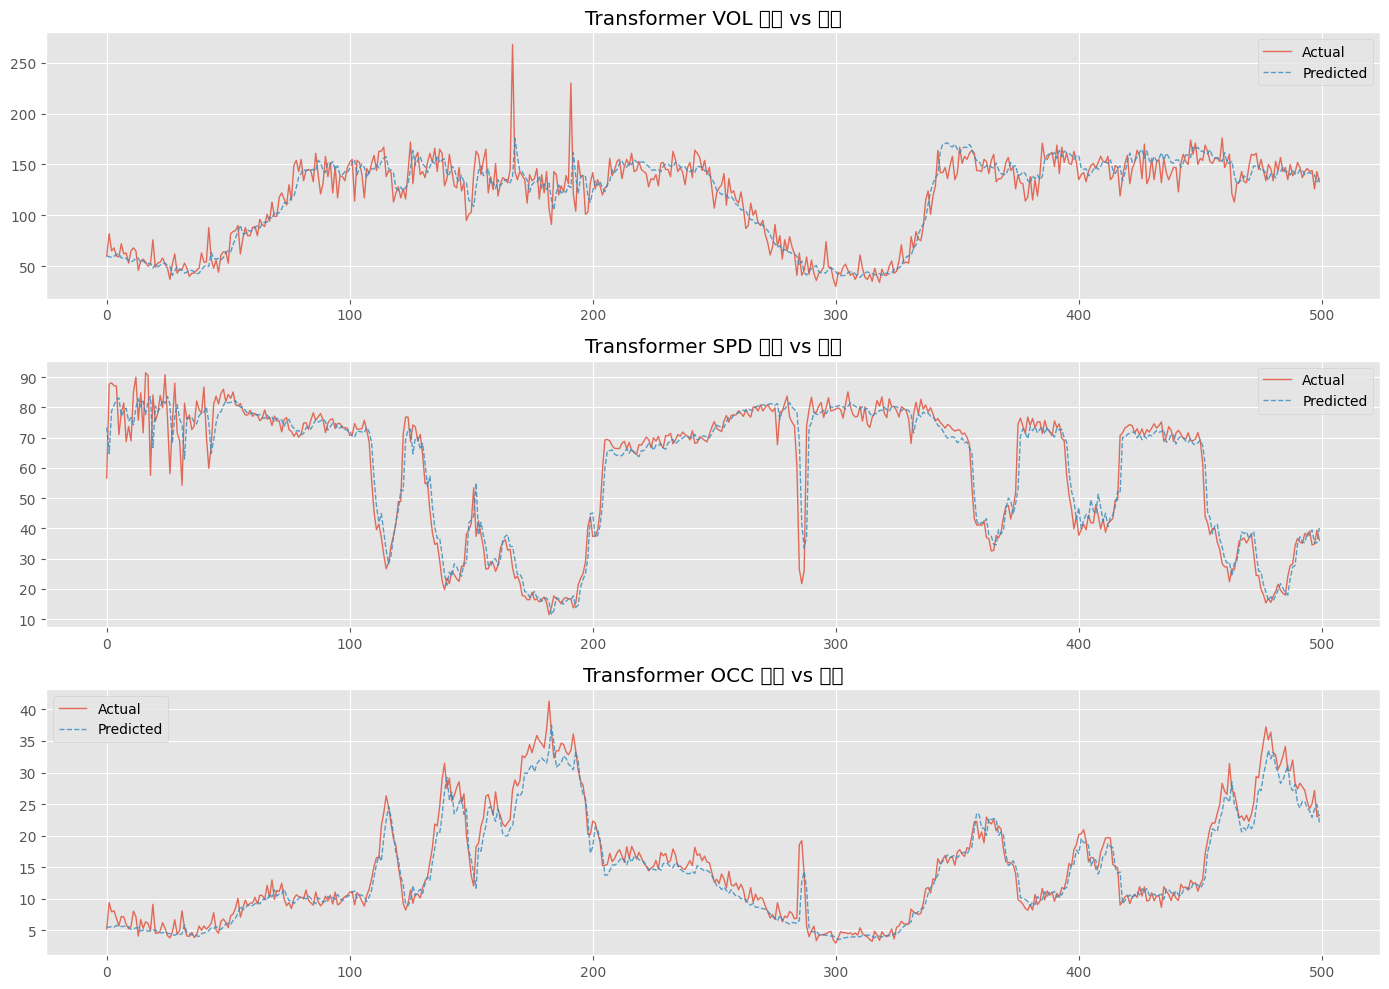

In [29]:
PLOT_N = 500
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for i, (name, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    p = inv_fn(preds[:PLOT_N, i])
    t = inv_fn(trues[:PLOT_N, i])
    axes[i].plot(t, label='Actual',    linewidth=1.0, alpha=0.8)
    axes[i].plot(p, label='Predicted', linewidth=1.0, alpha=0.8, linestyle='--')
    axes[i].set_title(f'Transformer {name} 예측 vs 실제')
    axes[i].legend(); axes[i].grid(True)
plt.tight_layout()
plt.savefig('tr_prediction_result.png', dpi=150)
plt.show()

## 11. 모델 저장 (앙상블용)
> Transformer 예측값(`preds`)과 LSTM 예측값을 합쳐서 앙상블할 때 사용합니다.

In [30]:
# 스케일러 저장
with open('tr_scalers.pkl', 'wb') as f:
    pickle.dump(scalers, f)

# 인코더 저장
with open('tr_encoders.pkl', 'wb') as f:
    pickle.dump({'route_enc': route_enc, 'link_enc': link_enc}, f)

# 모델 설정 저장
tr_model_config = {
    'model'                 : 'Transformer',
    'num_numeric_features'  : len(NUM_FEATURES),
    'num_routes'            : NUM_ROUTES,
    'route_emb_dim'         : ROUTE_EMB_DIM,
    'num_links'             : NUM_LINKS,
    'link_emb_dim'          : LINK_EMB_DIM,
    'd_model'               : _dm,
    'nhead'                 : _nh,
    'num_layers'            : _nl,
    'dim_ff'                : _df2,
    'dropout'               : _dr,
    'output_size'           : 3,
    'pred_steps'            : PRED_STEPS,
    'seq_len'               : SEQ_LEN,
    'num_features'          : NUM_FEATURES,
}
with open('tr_model_config.pkl', 'wb') as f:
    pickle.dump(tr_model_config, f)

# 앙상블용: 테스트 예측값 저장
np.save('tr_test_preds.npy', preds)
np.save('tr_test_trues.npy', trues)

print('저장 완료:')
print('  best_transformer_model.pt  ← 모델 가중치')
print('  tr_scalers.pkl             ← 스케일러')
print('  tr_encoders.pkl            ← 인코더')
print('  tr_model_config.pkl        ← 모델 설정')
print('  tr_test_preds.npy          ← 테스트 예측값 (앙상블용)')
print('  tr_test_trues.npy          ← 테스트 정답값 (앙상블용)')

저장 완료:
  best_transformer_model.pt  ← 모델 가중치
  tr_scalers.pkl             ← 스케일러
  tr_encoders.pkl            ← 인코더
  tr_model_config.pkl        ← 모델 설정
  tr_test_preds.npy          ← 테스트 예측값 (앙상블용)
  tr_test_trues.npy          ← 테스트 정답값 (앙상블용)
